# 1. Preamble & Introduction (Nazariy Savollar)

1. **O'lchamlar la'nati (Curse of Dimensionality):** k-NN, SVM kabi masofaga asoslangan modellar va chiziqli modellar uchun dolzarb. O'lchamlar ortishi bilan nuqtalar orasidagi masofalar kattalashadi, ma'lumotlar siyraklashadi va "eng yaqin qo'shni" tushunchasi o'z ma'nosini yo'qotadi.
2. **PCA va SVD farqi:** PCA ma'lumotlarning kovariatsiya matritsasiga tayanadi va markazlashtirishni (mean centering) talab qiladi. SVD esa ixtiyoriy matritsani to'g'ridan-to'g'ri ortogonal komponentlarga faktorizatsiya qiladi.
3. **NMF va SVD farqi:** NMF faqat musbat qiymatlar bilan ishlaydi va obyektlarni o'ziga xos "qismlar" yig'indisi sifatida ifodalaydi. SVD esa manfiy qiymatlarni ham qabul qila oladi.
4. **LLE (Locally Linear Embedding):** Algoritm uch bosqichda ishlaydi: (1) Har bir nuqta uchun k-eng yaqin qo'shnilarni topish. (2) Nuqtani qo'shnilarining chiziqli kombinatsiyasi sifatida ifodalovchi og'irliklarni topish. (3) Past o'lchamli fazoda shu og'irliklarni saqlab qolgan holda nuqtalar koordinatalarini hisoblash.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import cv2
import joblib
import warnings
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.datasets import fetch_openml
from sklearn.manifold import TSNE
import umap

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
%matplotlib inline
print("Kutubxonalar muvaffaqiyatli yuklandi.")

Kutubxonalar muvaffaqiyatli yuklandi.


In [ ]:
print("1. Ma'lumotlar yuklanmoqda (Books.csv bilan)...")
try:
    ratings = pd.read_csv('data/Ratings.csv')
    users = pd.read_csv('data/Users.csv')
    books = pd.read_csv('data/Books.csv', low_memory=False)
    
    users = users[(users['Age'] >= 5) & (users['Age'] <= 100)].dropna(subset=['Age'])
    
    data = ratings.merge(users[['User-ID', 'Age']], on='User-ID')
    data = data.merge(books[['ISBN']], on='ISBN')
    
    print(f"OK: Tozalangan ma'lumotlar soni: {len(data)}")
except FileNotFoundError:
    print("Xatolik: 'data/' papkasida CSV fayllar topilmadi!")

1. Ma'lumotlar yuklanmoqda (Books.csv bilan)...
OK: Tozalangan ma'lumotlar soni: 748667


In [ ]:
print("2. Siyrak matritsa (Interaction Matrix) yaratilmoqda...")
user_map = {id: i for i, id in enumerate(data['User-ID'].unique())}
book_map = {id: i for i, id in enumerate(data['ISBN'].unique())}

row = data['User-ID'].map(user_map).values
col = data['ISBN'].map(book_map).values
vals = data['Book-Rating'].values

X_sparse = csr_matrix((vals, (row, col)), shape=(len(user_map), len(book_map)))
y = data.groupby('User-ID')['Age'].first().values

X_temp, X_test, y_temp, y_test = train_test_split(X_sparse, y, test_size=0.2, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42) # 0.8 * 0.25 = 0.2

print(f"Matritsa shakli: {X_sparse.shape}")
print(f"Train: {X_train.shape[0]}, Valid: {X_valid.shape[0]}, Test: {X_test.shape[0]}")

y_baseline = np.full(y_test.shape, y_train.mean())
print(f"Baseline MAE: {mean_absolute_error(y_test, y_baseline):.2f}")

2. Siyrak matritsa (Interaction Matrix) yaratilmoqda...
Matritsa shakli: (53500, 228193)
Train: 32100, Valid: 10700, Test: 10700
Baseline MAE: 11.26


In [ ]:
print("3. Modellar o'qitilmoqda va solishtirilmoqda...\n")

def evaluate_models(X_tr, X_val, X_te, name):
    print(f"--- {name} MA'LUMOTLARI ---")
    
    start_lin = time.time()
    lin_model = Ridge(alpha=1.0)
    lin_model.fit(X_tr, y_train)
    time_lin = time.time() - start_lin
    mae_lin = mean_absolute_error(y_test, lin_model.predict(X_te))
    
    start_rf = time.time()
    rf_model = RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42, n_jobs=-1)
    rf_model.fit(X_tr, y_train)
    time_rf = time.time() - start_rf
    mae_rf = mean_absolute_error(y_test, rf_model.predict(X_te))
    
    print(f"Linear Model -> Vaqt: {time_lin:.2f}s | Test MAE: {mae_lin:.2f}")
    print(f"Random Forest -> Vaqt: {time_rf:.2f}s | Test MAE: {mae_rf:.2f}\n")

evaluate_models(X_train, X_valid, X_test, "ORIGINAL SPARSE FEATURES")

print("SVD orqali o'lchamlar kamaytirilmoqda...")
svd = TruncatedSVD(n_components=50, random_state=42)
X_train_svd = svd.fit_transform(X_train)
X_valid_svd = svd.transform(X_valid)
X_test_svd = svd.transform(X_test)

evaluate_models(X_train_svd, X_valid_svd, X_test_svd, "COMPRESSED (SVD n=50)")

print("UMAP orqali o'lchamlar kamaytirilmoqda (bir oz vaqt olishi mumkin)...")
reducer = umap.UMAP(n_components=10, random_state=42)
X_train_umap = reducer.fit_transform(X_train)
X_valid_umap = reducer.transform(X_valid)
X_test_umap = reducer.transform(X_test)

evaluate_models(X_train_umap, X_valid_umap, X_test_umap, "COMPRESSED (UMAP n=10)")

3. Modellar o'qitilmoqda va solishtirilmoqda...

--- ORIGINAL SPARSE FEATURES MA'LUMOTLARI ---
Linear Model -> Vaqt: 2.30s | Test MAE: 15.00
Random Forest -> Vaqt: 8.28s | Test MAE: 11.25

SVD orqali o'lchamlar kamaytirilmoqda...
--- COMPRESSED (SVD n=50) MA'LUMOTLARI ---
Linear Model -> Vaqt: 0.01s | Test MAE: 11.25
Random Forest -> Vaqt: 4.54s | Test MAE: 11.27

UMAP orqali o'lchamlar kamaytirilmoqda (bir oz vaqt olishi mumkin)...
--- COMPRESSED (UMAP n=10) MA'LUMOTLARI ---
Linear Model -> Vaqt: 0.00s | Test MAE: 11.26
Random Forest -> Vaqt: 1.05s | Test MAE: 11.28



4. MNIST tahlili (3000 namuna)...


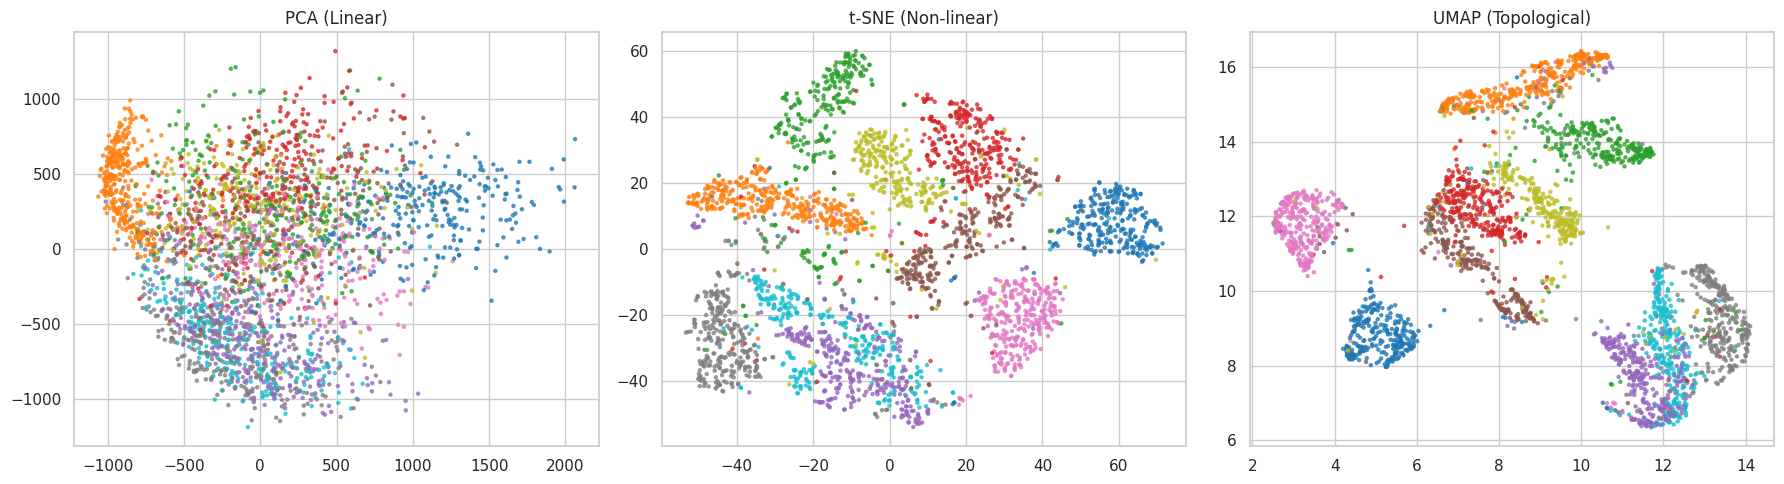

Model 'mnist_pca_model.pkl' fayliga saqlandi.


In [ ]:
print("4. MNIST tahlili (3000 namuna)...")
X_mnist, y_mnist = fetch_openml('mnist_784', version=1, as_frame=False, return_X_y=True)
X_sub, y_sub = X_mnist[:3000], y_mnist[:3000].astype(int) 

methods = {
    "PCA (Linear)": PCA(n_components=2),
    "t-SNE (Non-linear)": TSNE(n_components=2, random_state=42),
    "UMAP (Topological)": umap.UMAP(n_components=2, random_state=42)
}

plt.figure(figsize=(18, 5))
for i, (name, model) in enumerate(methods.items()):
    res = model.fit_transform(X_sub)
    plt.subplot(1, 3, i+1)
    plt.scatter(res[:, 0], res[:, 1], c=y_sub, cmap='tab10', s=5, alpha=0.7)
    plt.title(name)
plt.tight_layout()
plt.show()

# Modelni saqlash
joblib.dump(methods["PCA (Linear)"], 'mnist_pca_model.pkl')
print("Model 'mnist_pca_model.pkl' fayliga saqlandi.")

5. SVD Variatsiya tahlili va Rasm siqish...


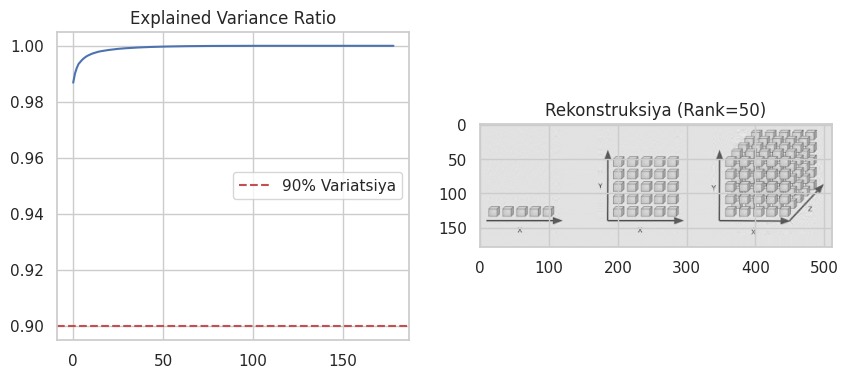

In [ ]:
print("5. SVD Variatsiya tahlili va Rasm siqish...")
try:
    img = cv2.imread('data/images/preamble.png', 0)
    U, S, Vt = np.linalg.svd(img, full_matrices=False)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(np.cumsum(S**2) / np.sum(S**2))
    plt.axhline(y=0.9, color='r', linestyle='--', label='90% Variatsiya')
    plt.title("Explained Variance Ratio")
    plt.legend()

    k = 50
    reconst = U[:, :k] @ np.diag(S[:k]) @ Vt[:k, :]
    plt.subplot(1, 2, 2)
    plt.imshow(reconst, cmap='gray')
    plt.title(f"Rekonstruksiya (Rank={k})")
    plt.show()
except Exception as e:
    print(f"Rasm fayli topilmadi: {e}")

6. Videodan fon ajratish (SVD Low-rank)...


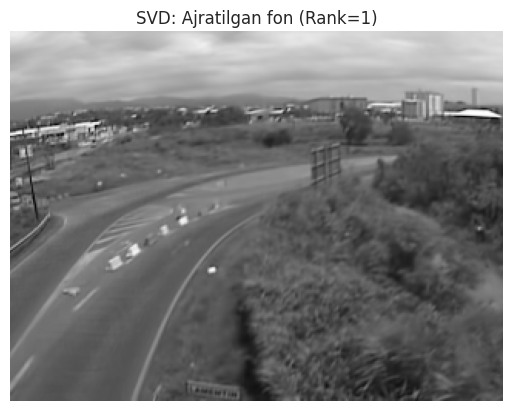

In [ ]:
def get_bg(video_path, k=1):
    cap = cv2.VideoCapture(video_path)
    frames = []
    for _ in range(120): 
        ret, frame = cap.read()
        if not ret: break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).flatten())
    cap.release()
    if not frames: return None
    
    M = np.array(frames).T
    U, S, Vt = np.linalg.svd(M, full_matrices=False)
    bg = U[:, :k] @ np.diag(S[:k]) @ Vt[:k, :]
    return bg[:, 0].reshape(frame.shape[:2])

print("6. Videodan fon ajratish (SVD Low-rank)...")
try:
    bg_frame = get_bg('data/Video_008.avi', k=1)
    if bg_frame is not None:
        plt.imshow(bg_frame, cmap='gray')
        plt.title("SVD: Ajratilgan fon (Rank=1)")
        plt.axis('off')
        plt.show()
    else:
        print("Video kadrlarini o'qishda xatolik yuz berdi.")
except Exception as e:
    print(f"Video fayli topilmadi: {e}")

In [ ]:
loaded_pca = joblib.load('mnist_pca_model.pkl')
sample_test = X_sub[0].reshape(1, -1)
print(f"MNIST namunasi 2D koordinatalari: {loaded_pca.transform(sample_test)}")

MNIST namunasi 2D koordinatalari: [[163.26834263 346.42603085]]


Bonus qism: Yuz ifodalarini manipulyatsiya qilish boshlandi...
fer2013.csv yuklanmoqda...
Rasmlar tayyorlanmoqda (48x48 piksellar)...
PCA modeli o'qitilmoqda (n_components=300)...


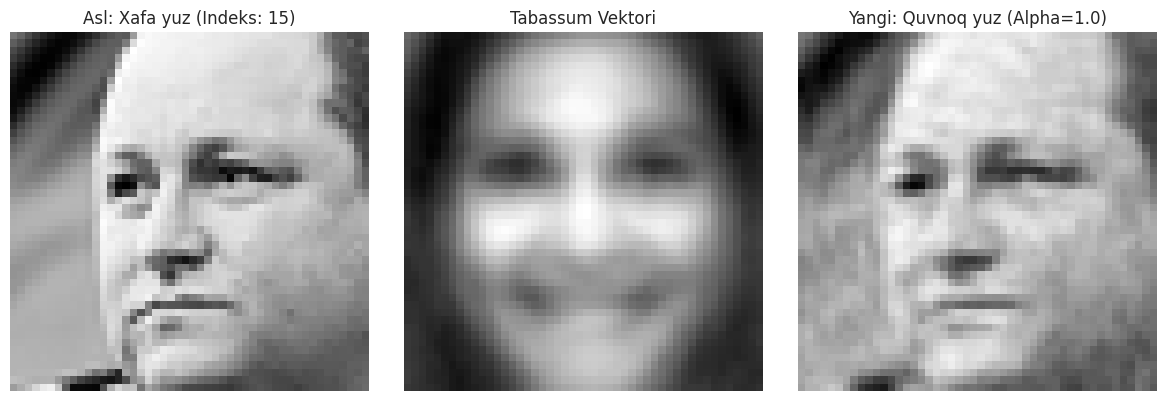

Bonus qism muvaffaqiyatli yakunlandi!


In [ ]:
print("Bonus qism: Yuz ifodalarini manipulyatsiya qilish boshlandi...")

try:
    print("fer2013.csv yuklanmoqda...")
    df = pd.read_csv('data/fer2013.csv')

    happy_df = df[df['emotion'] == 3].head(1000)
    sad_df = df[df['emotion'] == 4].head(1000)

    def parse_pixels(pixel_sequence):
        return np.array(pixel_sequence.split(' '), dtype=float)

    print("Rasmlar tayyorlanmoqda (48x48 piksellar)...")
    X_happy = np.array([parse_pixels(p) for p in happy_df['pixels']]) / 255.0
    X_sad = np.array([parse_pixels(p) for p in sad_df['pixels']]) / 255.0
    X_all = np.vstack((X_happy, X_sad))

    print("PCA modeli o'qitilmoqda (n_components=300)...")
    pca = PCA(n_components=300, random_state=42)
    pca.fit(X_all)

    latent_happy = pca.transform(X_happy)
    latent_sad = pca.transform(X_sad)

    v_happy_mean = latent_happy.mean(axis=0)
    v_sad_mean = latent_sad.mean(axis=0)
    v_smile = v_happy_mean - v_sad_mean

    tanlangan_indeks = 15  
    
    target_sad_latent = latent_sad[tanlangan_indeks]              
    original_sad_face = X_sad[tanlangan_indeks].reshape(48, 48)   

    alpha = 1.0 
    new_happy_latent = target_sad_latent + (alpha * v_smile)

    new_happy_face = pca.inverse_transform(new_happy_latent.reshape(1, -1)).reshape(48, 48)
    smile_face = pca.inverse_transform(v_smile.reshape(1, -1)).reshape(48, 48)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original_sad_face, cmap='gray')
    plt.title(f"Asl: Xafa yuz (Indeks: {tanlangan_indeks})")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(smile_face, cmap='gray')
    plt.title("Tabassum Vektori")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(new_happy_face, cmap='gray')
    plt.title(f"Yangi: Quvnoq yuz (Alpha={alpha})")
    plt.axis('off')

    plt.tight_layout()
    plt.show()
    print("Bonus qism muvaffaqiyatli yakunlandi!")

except Exception as e:
    print(f"Kutilmagan xatolik yuz berdi: {e}")